In [2]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Project directory
PROJECT_DIR = Path.cwd().parent

# Dataset paths
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

TRAIN_CSV = PROCESSED_DIR / "train.csv"
VAL_CSV = PROCESSED_DIR / "validation.csv"
TEST_CSV = PROCESSED_DIR / "test.csv"

# Model directory
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Configuration
IMG_SIZE = 128
BATCH_SIZE = 16
SEED = 42

print("TensorFlow Version:", tf.__version__)
print("Project Directory:", PROJECT_DIR)
print("Model Directory:", MODEL_DIR)

print("Training CSV:", TRAIN_CSV.exists())
print("Validation CSV:", VAL_CSV.exists())
print("Testing CSV:", TEST_CSV.exists())

TensorFlow Version: 2.21.0
Project Directory: c:\Banana Sense-AI
Model Directory: c:\Banana Sense-AI\models
Training CSV: True
Validation CSV: True
Testing CSV: True


In [3]:
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

class_names = sorted(train_df["label"].unique())

label_to_id = {
    label: index for index, label in enumerate(class_names)
}

id_to_label = {
    index: label for label, index in label_to_id.items()
}

print("\nClasses:", class_names)
print("Label mapping:", label_to_id)

Training images: 573
Validation images: 123
Testing images: 123

Classes: ['Green', 'Overripe', 'Ripe', 'Semi-ripe']
Label mapping: {'Green': 0, 'Overripe': 1, 'Ripe': 2, 'Semi-ripe': 3}


In [4]:
data_augmentation = tf.keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="data_augmentation")

print("Data augmentation recreated successfully!")
print("Input shape:", data_augmentation.input_shape)

Data augmentation recreated successfully!
Input shape: (None, 128, 128, 3)


In [5]:
model_v2 = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(len(class_names), activation="softmax")
])

print("Improved CNN created successfully!")

Improved CNN created successfully!


In [6]:
model_v2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,948 (433.39 KB)

 Trainable params: 110,500 (431.64 KB)

 Non-trainable params: 448 (1.75 KB)

In [7]:
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Version 2 compiled successfully!")

CNN Version 2 compiled successfully!


In [8]:
callbacks_v2 = [

    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_banana_cnn_v2.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

print("Callbacks configured successfully!")

Callbacks configured successfully!


In [10]:
history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks_v2
)

NameError: name 'train_ds' is not defined

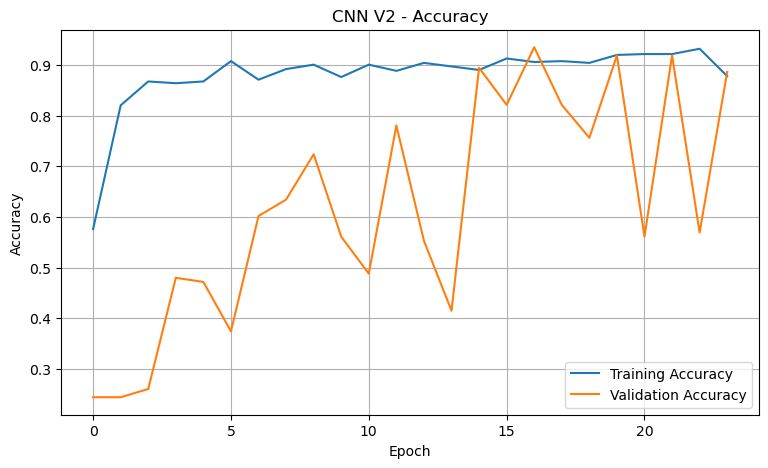

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(history_v2.history["accuracy"], label="Training Accuracy")
plt.plot(history_v2.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN V2 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

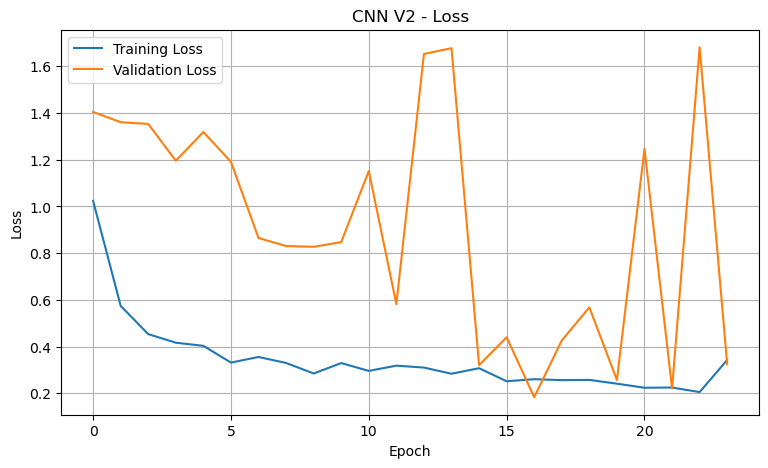

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(history_v2.history["loss"], label="Training Loss")
plt.plot(history_v2.history["val_loss"], label="Validation Loss")

plt.title("CNN V2 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
BEST_MODEL_V2_PATH = MODEL_DIR / "best_banana_cnn_v2.keras"

print("Checkpoint exists:", BEST_MODEL_V2_PATH.exists())

best_model_v2 = tf.keras.models.load_model(
    BEST_MODEL_V2_PATH
)

print("Best CNN V2 loaded successfully!")

Checkpoint exists: True
Best CNN V2 loaded successfully!


In [ ]:
test_loss_v2, test_accuracy_v2 = best_model_v2.evaluate(test_ds)

print(f"V2 Test Accuracy: {test_accuracy_v2 * 100:.2f}%")
print(f"V2 Test Loss: {test_loss_v2:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.9431 - loss: 0.1636
V2 Test Accuracy: 94.31%
V2 Test Loss: 0.1636


In [ ]:
# Generate predictions
y_pred_probs_v2 = best_model_v2.predict(test_ds)

# Convert probabilities into class IDs
y_pred_v2 = np.argmax(y_pred_probs_v2, axis=1)

# Extract actual labels
y_true_v2 = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

print("Actual labels:", y_true_v2[:10])
print("Predicted labels:", y_pred_v2[:10])

print("Predictions generated successfully!")


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step
Actual labels: [2 2 2 1 3 3 0 1 2 0]
Predicted labels: [2 2 0 1 3 3 0 1 2 0]
Predictions generated successfully!


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true_v2,
        y_pred_v2,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       Green       0.97      1.00      0.98        32
    Overripe       1.00      0.94      0.97        31
        Ripe       0.90      0.90      0.90        30
   Semi-ripe       0.90      0.93      0.92        30

    accuracy                           0.94       123
   macro avg       0.94      0.94      0.94       123
weighted avg       0.94      0.94      0.94       123



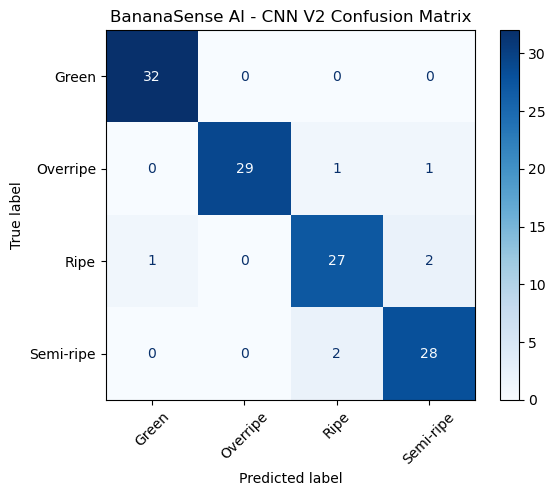

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_true_v2,
    y_pred_v2,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("BananaSense AI - CNN V2 Confusion Matrix")
plt.show()

In [ ]:
# Load original CNN checkpoint
best_model_v1 = tf.keras.models.load_model(
    MODEL_DIR / "best_banana_cnn.keras"
)

# Evaluate on test dataset
test_loss_v1, test_accuracy_v1 = best_model_v1.evaluate(test_ds)

print(f"CNN V1 Test Accuracy: {test_accuracy_v1 * 100:.2f}%")
print(f"CNN V1 Test Loss: {test_loss_v1:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8862 - loss: 0.2465
CNN V1 Test Accuracy: 88.62%
CNN V1 Test Loss: 0.2465


In [ ]:
comparison = pd.DataFrame({
    "Model": ["CNN Version 1", "CNN Version 2"],
    "Test Accuracy": [
        test_accuracy_v1 * 100,
        test_accuracy_v2 * 100
    ],
    "Test Loss": [
        test_loss_v1,
        test_loss_v2
    ]
})

display(comparison)

,Model,Test Accuracy,Test Loss
0,CNN Version 1,88.617885,0.246508
1,CNN Version 2,94.308943,0.163571


In [ ]:
from pathlib import Path
import tensorflow as tf

PROJECT_DIR = Path.cwd().parent
MODEL_DIR = PROJECT_DIR / "models"

FINAL_MODEL_PATH = MODEL_DIR / "banana_sense_ai_final.keras"

print("Model directory:", MODEL_DIR)
print("Model exists:", FINAL_MODEL_PATH.exists())

Model directory: c:\Banana Sense-AI\models
Model exists: True


In [ ]:
final_model = tf.keras.models.load_model(FINAL_MODEL_PATH)

print("Model loaded successfully!")
print("Input shape:", final_model.input_shape)
print("Output shape:", final_model.output_shape)

Model loaded successfully!
Input shape: (None, 128, 128, 3)
Output shape: (None, 4)


In [ ]:
sample_image_path = test_df.iloc[0]["image_path"]

print("Selected image:", sample_image_path)

Selected image: C:\Banana Sense-AI\data\raw\Banana Ripeness Detection Dataset\Ripe\Ripe_23.jpg


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step


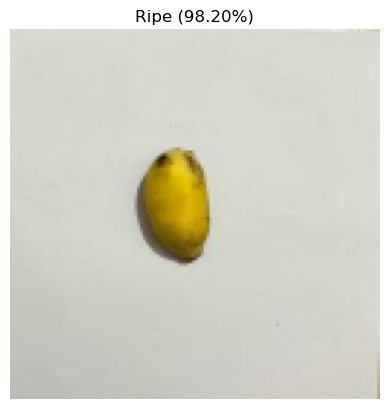

Predicted class: Ripe
Confidence: 98.20%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Load and preprocess image
image = tf.io.read_file(sample_image_path)
image = tf.io.decode_image(image, channels=3)
image = tf.image.resize(image, [128, 128])
image = image / 255.0

# Add batch dimension
image_batch = tf.expand_dims(image, axis=0)

# Predict
predictions = final_model.predict(image_batch)

predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

# Display image and prediction
plt.imshow(image.numpy())
plt.axis("off")
plt.title(f"{predicted_class} ({confidence:.2f}%)")
plt.show()

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

In [11]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent

train_df = pd.read_csv(
    PROJECT_DIR / "data" / "processed" / "train.csv"
)

class_names = sorted(train_df["label"].unique().tolist())

print(class_names)

['Green', 'Overripe', 'Ripe', 'Semi-ripe']
